In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from itertools import combinations
from scipy import stats
import networkx as nx
import plotly.graph_objects as go
from IPython.display import display

### Analysis 1: Did Michael's departure cause a break, or was it a continuing decline?

In [2]:
df = pd.read_csv("episodes_merged.csv", parse_dates=["Air Date"])
scripts = pd.read_csv("script_clean.csv")
CUT = 148

In [3]:
# Sanity checks on the cut
assert df.loc[df["Overall No"] == CUT, "Title"].item() == "Goodbye, Michael"
assert (df.loc[df["Overall No"] > CUT, "michael_share"] < 0.01).all()
assert (df.loc[df["Overall No"] <= CUT, "michael_lines"] > 0).all()

In [4]:
# Drop the Super Bowl episode (22.9M viewers is an outlier unrelated to Michael)
d = df[~df["is_superbowl"]].copy()
d["episodes_since_cut"] = d["Overall No"] - CUT               
d["after_michael"] = (d["Overall No"] > CUT).astype(int)
d["slope_change"] = d["episodes_since_cut"] * d["after_michael"]
print(d.groupby("after_michael")[["Viewers", "Rating"]].agg(["mean", "std", "count"]).round(2))


              Viewers             Rating            
                 mean   std count   mean   std count
after_michael                                       
0                7.97  1.04   135   8.38  0.50   135
1                4.90  1.04    50   7.77  0.62    50


In [5]:
models = {y: smf.ols(f"{y} ~ episodes_since_cut + after_michael + slope_change", d).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
          for y in ["Viewers", "Rating"]}
for y, m in models.items():
    print(y)
    print(m.summary().tables[1], "\n")


Viewers
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              7.5749      0.214     35.428      0.000       7.156       7.994
episodes_since_cut    -0.0054      0.004     -1.483      0.138      -0.012       0.002
after_michael         -1.1090      0.349     -3.175      0.001      -1.794      -0.424
slope_change          -0.0538      0.010     -5.123      0.000      -0.074      -0.033

Rating
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              8.2831      0.119     69.515      0.000       8.050       8.517
episodes_since_cut    -0.0013      0.001     -0.969      0.332      -0.004       0.001
after_michael         -0.7432      0.299     -2.484      0.013      -1.330      -0.157
slope_change           0.00

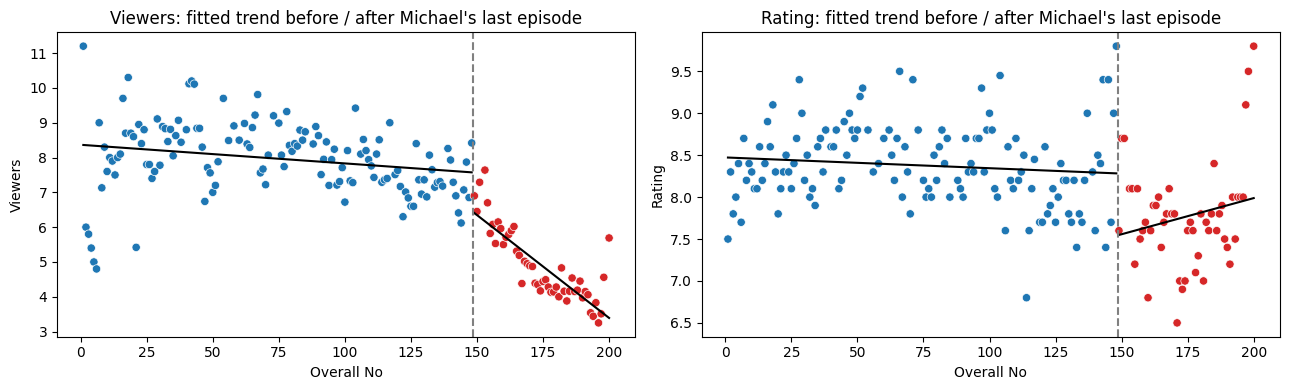

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, y in zip(axes, ["Viewers", "Rating"]):
    m = models[y]
    sns.scatterplot(data=d, x="Overall No", y=y, hue="after_michael", palette=["tab:blue", "tab:red"], legend=False, ax=ax)
    for post, g in d.groupby("after_michael"):
        ax.plot(g["Overall No"], m.predict(g), color="black")
    ax.axvline(CUT + 0.5, ls="--", color="grey")
    ax.set_title(f"{y}: fitted trend before / after Michael's last episode")
plt.tight_layout()


#### Conclusion

Michael Scott's departure marks a **real break** in the show's viewership, not a continuation of an earlier decline.

| | Pre-departure trend | Immediate drop at the cut | Slope change after |
|---|---|---|---|
| **Viewers** | Flat (-0.005M per episode, not significant) | -1.11M (p = 0.001) | -0.054M per episode (p < 0.001) |
| **Rating** | Flat (-0.001 per episode, not significant) | -0.74 points (p = 0.013) | +0.01 (not significant) |

- **Viewers:** the audience was stable before Michael left. It dropped by about 1.1M at his exit, then kept falling.
- **Ratings:** they fell at the cut, then levelled off at a lower plateau. Season 9 recovered slightly (mean 7.58 in season 8, 7.90 in season 9).

**Limitations**
- There is no control group, so the analysis shows a break at Michael's exit but does not prove he caused it.
- Season 7 already gave him less screen time (share 0.20, against about 0.27-0.30 earlier), and other changes happened around the same time.
- The cut is set by hand, not estimated.

**Takeaway:** Michael's exit coincided with a sharp, lasting loss of audience and a lower rating level. His absence is a plausible cause, but the data cannot prove it.


### Analysis 2: How did the structure of character interactions change after Michael Scott left, and did the show become more centered on a few characters or more evenly spread?

In [7]:
# Merging Script to Episodes
ep_map = df[["Season", "Script Ep No", "Overall No"]].rename(columns={"Season": "season", "Script Ep No": "episode"})
sc = scripts.merge(ep_map, on=["season", "episode"], how="left", validate="many_to_one")
assert sc["Overall No"].notna().all()
sc["era"] = np.where(sc["Overall No"] <= CUT, "Michael", "Post-Michael")

In [ ]:
# Maintain list for cast with 300+ lines
counts = sc["speaker"].value_counts()
cast = counts[counts >= 300].index.tolist()

In [9]:
# Helper Functions
def pair_counts(scenes):
    return pd.Series([p for chars in scenes["chars"] for p in combinations(chars, 2)]).value_counts()

def adjacency(scenes):
    A = pd.DataFrame(0.0, index=cast, columns=cast)
    for (a, b), n in pair_counts(scenes).items():
        A.loc[a, b] = A.loc[b, a] = n
    return A

def eigenvector_centrality(A):
    vals, vecs = np.linalg.eigh(A.values)
    v = np.abs(vecs[:, -1])
    return pd.Series(v / v.sum(), index=A.index)

In [10]:
# One row per scene: which cast members speak in it
scenes = (sc[sc["speaker"].isin(cast)]
          .groupby(["season", "episode", "scene", "era"])["speaker"]
          .agg(lambda s: sorted(set(s))).reset_index(name="chars"))

##### Sub-question 1: Who is central?

In [11]:
def centrality_table(scenes):
    A = adjacency(scenes)
    n = len(scenes)
    return pd.DataFrame({
        "scene_share": [sum(c in ch for ch in scenes["chars"]) / n for c in cast],  # share of scenes the character is in
        "partners": (A > 0).sum(),                                                 # distinct characters they share a scene with
        "weighted_degree": A.sum() / n,                                            # shared-scene count per scene
        "eigenvector": eigenvector_centrality(A)}, index=cast)


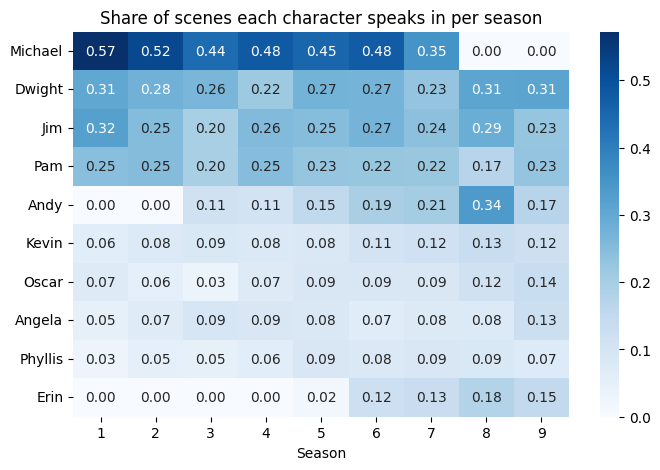

In [12]:
season_share = pd.concat({s: centrality_table(g)["scene_share"] for s, g in scenes.groupby("season")}, axis=1)
top = season_share.mean(axis=1).nlargest(10).index

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(season_share.loc[top], annot=True, fmt=".2f", cmap="Blues", ax=ax)
ax.set_xlabel("Season"); ax.set_title("Share of scenes each character speaks in per season")
plt.show()


In [13]:
by_era = pd.concat({e: centrality_table(g) for e, g in scenes.groupby("era")}, axis=1)
by_era.sort_values(("Michael", "scene_share"), ascending=False).head(12).round(3)


Michael                                      Post-Michael  \
        scene_share partners weighted_degree eigenvector  scene_share   
Michael       0.466       21           0.658       0.134        0.001   
Dwight        0.259       21           0.458       0.113        0.308   
Jim           0.241       21           0.451       0.112        0.264   
Pam           0.226       21           0.422       0.105        0.203   
Andy          0.122       21           0.261       0.060        0.246   
Kevin         0.089       22           0.249       0.055        0.132   
Angela        0.079       21           0.212       0.048        0.102   
Oscar         0.068       21           0.213       0.048        0.123   
Phyllis       0.067       21           0.225       0.051        0.083   
Ryan          0.067       22           0.153       0.039        0.047   
Kelly         0.054       21           0.149       0.032        0.039   
Stanley       0.051       21           0.165       0.039        0.061   

                                              
        partners weighted_degree eigenvector  
Michael        2           0.001       0.000  
Dwight        21           0.553       0.100  
Jim           20           0.542       0.100  
Pam           20           0.455       0.086  
Andy          20           0.501       0.087  
Kevin         18           0.400       0.071  
Angela        18           0.290       0.055  
Oscar         18           0.371       0.066  
Phyllis       19           0.320       0.059  
Ryan          18           0.132       0.024  
Kelly         18           0.135       0.025  
Stanley       19           0.211       0.040

In [14]:
ERAS = ["Michael", "Post-Michael"]
era_scenes = {e: scenes[scenes["era"] == e] for e in ERAS}
counts = {e: pair_counts(era_scenes[e]) for e in ERAS}
n_scenes = {e: len(era_scenes[e]) for e in ERAS}

def scene_share(g, members=cast):
    return pd.Series({c: sum(c in ch for ch in g["chars"]) for c in members}) / len(g)

def build_graph(g, thr=0.0, members=cast, min_node=0.0):
    n = len(g); share = scene_share(g, members)
    G = nx.Graph()
    G.add_nodes_from((c, {"share": share[c]}) for c in members)
    for (a, b), w in pair_counts(g).items():
        if a in share.index and b in share.index and w / n >= thr:
            G.add_edge(a, b, share=w / n, weight=w / n)          # `weight` is used by the network metrics
    G.remove_nodes_from([c for c in members if share[c] < min_node])
    return G


In [15]:
G_all = nx.Graph()
G_all.add_nodes_from(cast)
pc = pair_counts(scenes)
for (a, b), w in pc.items():
    G_all.add_edge(a, b, weight=np.log1p(w)) 

In [16]:
# Michael at the centre, others on a ring. Radius = how rarely they share scenes with Michael.
# Angular order comes from the spring layout, so related characters stay near each other.
sp = nx.spring_layout(G_all, weight="weight", k=1.2 / np.sqrt(len(cast)), iterations=300, seed=3)
with_mike = {c: pc.get((min(c, "Michael"), max(c, "Michael")), 0) for c in cast if c != "Michael"}
mx = max(with_mike.values())
others = sorted(with_mike, key=lambda c: np.arctan2(sp[c][1] - sp["Michael"][1], sp[c][0] - sp["Michael"][0]))
pos = {"Michael": np.array([0.0, 0.0])}
for i, c in enumerate(others):
    ang = 2 * np.pi * i / len(others)
    r = 1.0 - 0.6 * np.sqrt(with_mike[c] / mx)       
    pos[c] = np.array([r * np.cos(ang), r * np.sin(ang)])


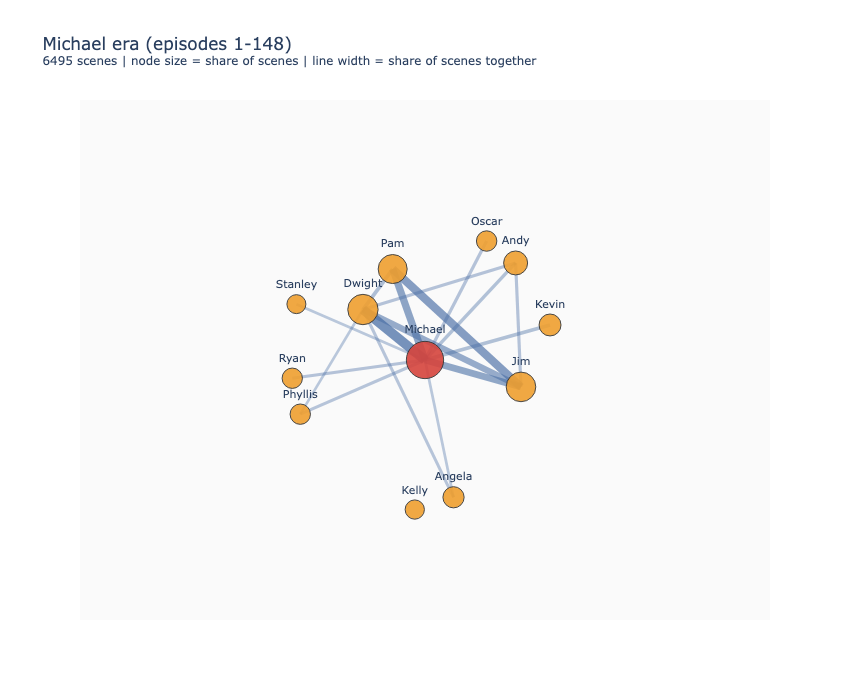

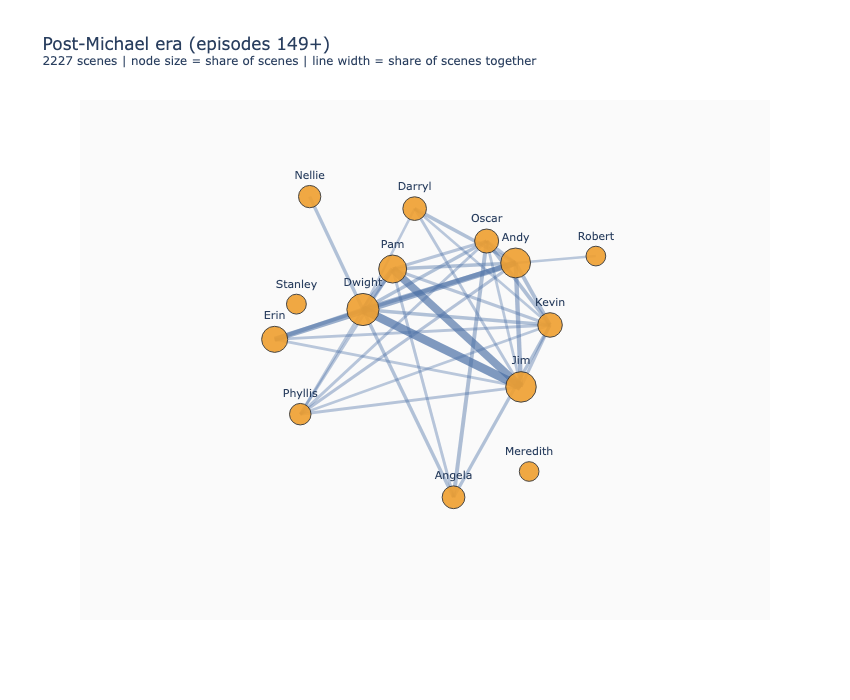

In [24]:
MIN_EDGE = 0.025           # hide pairs sharing under 2.5% of that era's scenes
MIN_NODE = 0.05            # hide characters in under 5% of that era's scenes
plot_graphs = {e: build_graph(era_scenes[e], MIN_EDGE, min_node=MIN_NODE) for e in ERAS} 
MAX_EDGE = max(d["share"] for G in plot_graphs.values() for _, _, d in G.edges(data=True))

def network_fig(era):
    G = plot_graphs[era]
    label = f"Michael era (episodes 1-{CUT})" if era == "Michael" else f"Post-Michael era (episodes {CUT + 1}+)"
    fig = go.Figure()
    for a, b, d in G.edges(data=True):               
        fig.add_trace(go.Scatter(x=[pos[a][0], pos[b][0]], y=[pos[a][1], pos[b][1]], mode="lines",
                                 line=dict(width=0.5 + 9 * d["share"] / MAX_EDGE,
                                           color=f"rgba(74,111,165,{0.25 + 0.5 * d['share'] / MAX_EDGE:.2f})"),
                                 hoverinfo="skip", showlegend=False))
    mid = [((pos[a][0] + pos[b][0]) / 2, (pos[a][1] + pos[b][1]) / 2, f"{a} / {b}: {d['share']:.1%} of scenes")
           for a, b, d in G.edges(data=True)]
    fig.add_trace(go.Scatter(x=[m[0] for m in mid], y=[m[1] for m in mid], mode="markers",
                             hovertext=[m[2] for m in mid], hoverinfo="text",
                             marker=dict(size=8, opacity=0), showlegend=False))   
    nodes = list(G.nodes)
    fig.add_trace(go.Scatter(
        x=[pos[c][0] for c in nodes], y=[pos[c][1] for c in nodes], mode="markers+text",
        text=nodes, textposition="top center", textfont=dict(size=11),
        hovertext=[f"{c}: in {G.nodes[c]['share']:.0%} of scenes, {G.degree(c)} partners" for c in nodes], hoverinfo="text",
        marker=dict(opacity=0.9, size=[10 + 40 * np.sqrt(G.nodes[c]["share"]) for c in nodes],
                    line=dict(width=1, color="#333"),
                    color=["#d6453d" if c == "Michael" else "#f0a030" for c in nodes]), showlegend=False))
    fig.update_layout(
        title=f"{label}<br><sup>{n_scenes[era]} scenes | node size = share of scenes | line width = share of scenes together</sup>",
        width=850, height=700, plot_bgcolor="#fafafa",
        xaxis=dict(visible=False, range=[-1.3, 1.3]), yaxis=dict(visible=False, range=[-1.3, 1.3], scaleanchor="x"))
    return fig

for e in ERAS:
    network_fig(e).show(renderer="notebook_connected+png")

**Conclusion**

Michael was the hub: he spoke in 46.6% of scenes in his era, against 25.9% for Dwight, 24.1% for Jim and 22.6% for Pam. After the cut his share is 0.1% (a cameo).

- **Who gained:** Andy roughly doubled (12.2% → 24.6%), Oscar rose from 6.8% to 12.3% and Kevin from 8.9% to 13.2%. Dwight rose from 25.9% to 30.8% and led the post-Michael era, while Pam fell from 22.6% to 20.3%.
- **Weighted degree** (shared scenes per scene) rose for Dwight (0.46 → 0.55), Jim (0.45 → 0.54) and especially Andy (0.26 → 0.50).
- Partner counts (18 to 22 of 23) barely separate characters, so they say little here.

##### Sub-question 2: Which relationships carry the show, and did the show rely on fewer pairs or more after Michael left?

In [18]:
tbl = pd.concat({e: counts[e] / n_scenes[e] * 100 for e in ERAS}, axis=1).fillna(0)
tbl["rank_Michael"] = tbl["Michael"].rank(ascending=False, method="min")
tbl["rank_Post"] = tbl["Post-Michael"].rank(ascending=False, method="min")
tbl.index = [f"{a} / {b}" for a, b in tbl.index]
tbl = tbl.rename(columns={"Michael": "% scenes (Michael)", "Post-Michael": "% scenes (Post)"})

top = tbl[(tbl["rank_Michael"] <= 10) | (tbl["rank_Post"] <= 10)].sort_values("rank_Post")
display(top.round(1))

,% scenes (Michael),% scenes (Post),rank_Michael,rank_Post
Dwight / Jim,7.1,9.8,5.0,1.0
Jim / Pam,9.3,8.8,2.0,2.0
Andy / Erin,1.4,6.3,52.0,3.0
Dwight / Pam,4.1,5.3,6.0,4.0
Andy / Dwight,3.4,5.0,9.0,5.0
Andy / Jim,3.2,4.8,12.0,6.0
Dwight / Erin,0.8,4.4,87.0,7.0
Angela / Oscar,1.6,4.2,43.0,8.0
Andy / Kevin,1.8,4.0,38.0,9.0
Kevin / Oscar,2.2,4.0,21.0,10.0


In [19]:
conc = pd.DataFrame({e: {"scenes": n_scenes[e],
                         "distinct pairs": len(counts[e]),
                         "top-5 share of pair-appearances": counts[e].head(5).sum() / counts[e].sum(),
                         "top-10 share": counts[e].head(10).sum() / counts[e].sum()} for e in ERAS})
display(conc.round(3))

t10 = {e: set(counts[e].head(10).index) for e in ERAS}
print("In both top-10s:", sorted(" / ".join(p) for p in t10["Michael"] & t10["Post-Michael"]))
print("Michael-era only:", sorted(" / ".join(p) for p in t10["Michael"] - t10["Post-Michael"]))
print("Post-era only:   ", sorted(" / ".join(p) for p in t10["Post-Michael"] - t10["Michael"]))


,Michael,Post-Michael
scenes,6495.000,2227.000
distinct pairs,226.000,188.000
top-5 share of pair-appearances,0.202,0.130
top-10 share,0.286,0.209


In both top-10s: ['Andy / Dwight', 'Dwight / Jim', 'Dwight / Pam', 'Jim / Pam']
Michael-era only: ['Andy / Michael', 'Dwight / Michael', 'Jim / Michael', 'Kevin / Michael', 'Michael / Pam', 'Michael / Ryan']
Post-era only:    ['Andy / Erin', 'Andy / Jim', 'Andy / Kevin', 'Angela / Oscar', 'Dwight / Erin', 'Kevin / Oscar']


**Conclusion**

Pair appearances became less concentrated after Michael left, but part of that is simply his pairs disappearing.

- **Concentration:** the top 5 pairs hold 20.2% of pair-appearances in the Michael era vs 13.0% after, and the top 10 hold 28.6% vs 20.9%. Six of the Michael-era top 10 involved Michael.
- **Leading pair:** Dwight / Michael had 11.0% of scenes. After the cut the leader, Dwight / Jim, has 9.8%, so the top pair itself changed little.
- **What persisted:** Jim / Pam, Dwight / Jim, Dwight / Pam and Andy / Dwight stay in the top 10.
- **What emerged:** Andy / Erin (1.4% → 6.3%), Dwight / Erin (0.8% → 4.4%) and Angela / Oscar (1.6% → 4.2%).
- **Distinct pairs** fell from 226 to 188, but the post-Michael era has about a third as many scenes, so this is not evidence of a narrower show.

##### Sub-question 3: Did the network fragment after Michael? Is it more concentrated around a few characters, or more evenly connected?

In [20]:
# Helper Functions
def gini(v):
    v = np.sort(np.asarray(v, float)); n = len(v)
    return (2 * np.arange(1, n + 1) - n - 1).dot(v) / (n * v.sum())

def net_metrics(x, thr=0.0):
    core = [c for c in cast if c != "Michael"]
    G = build_graph(x, thr, members=core)               
    strength = pd.Series(dict(G.degree(weight="weight")))
    return {"density": nx.density(G),
            "strength Gini": gini(strength),
            "top-3 strength share": strength.nlargest(3).sum() / strength.sum()}

In [21]:
for thr in (0.0, 0.01, 0.025):
    print(f"Edge threshold: pair in at least {thr:.1%} of the era's scenes")
    display(pd.DataFrame({e: net_metrics(era_scenes[e], thr) for e in ERAS}).round(3))

Edge threshold: pair in at least 0.0% of the era's scenes


,Michael,Post-Michael
density,0.810,0.735
strength Gini,0.465,0.413
top-3 strength share,0.356,0.294


Edge threshold: pair in at least 1.0% of the era's scenes


,Michael,Post-Michael
density,0.182,0.375
strength Gini,0.644,0.504
top-3 strength share,0.485,0.342


Edge threshold: pair in at least 2.5% of the era's scenes


,Michael,Post-Michael
density,0.028,0.138
strength Gini,0.835,0.651
top-3 strength share,0.812,0.443


In [22]:
rng = np.random.default_rng(0)
for e in ERAS:
    x = scenes[scenes["era"] == e]
    groups = x.groupby(["season", "episode"]).groups
    keys = list(groups); vals = []
    for _ in range(100):
        pick = rng.choice(len(keys), len(keys))
        xb = pd.concat([x.loc[groups[keys[i]]] for i in pick])
        m = net_metrics(xb, 0.0); vals.append((m["strength Gini"], m["top-3 strength share"]))
    v = np.array(vals)
    print(f"{e}: strength Gini 95% CI {np.percentile(v[:, 0], [2.5, 97.5]).round(3)}, "
          f"top-3 share 95% CI {np.percentile(v[:, 1], [2.5, 97.5]).round(3)}")


Michael: strength Gini 95% CI [0.45  0.485], top-3 share 95% CI [0.34  0.374]
Post-Michael: strength Gini 95% CI [0.399 0.439], top-3 share 95% CI [0.278 0.312]


**Conclusion**

After Michael left, interaction strength among the remaining cast was spread more evenly across characters. The evidence on whether the network became more or less connected is mixed, and none of these measures shows it fragmenting. Michael is excluded as a character from both eras, and the cast is the 300+ line characters pooled across the whole series.

| Edge threshold (pair must share at least this % of the era's scenes) | 0% | 1% | 2.5% |
|---|---|---|---|
| Strength Gini (Michael → Post) | 0.465 → 0.413 | 0.644 → 0.504 | 0.835 → 0.651 |
| Top-3 characters' share of total strength | 35.6% → 29.4% | 48.5% → 34.2% | 81.2% → 44.3% |
| Density | 0.81 → 0.74 | 0.18 → 0.38 | 0.03 → 0.14 |

**Concentration fell (consistent across thresholds)**
- Both concentration measures are lower after the cut at all three thresholds.
- The 0% column is the cleanest comparison. Every pair counts, and the number of scenes cancels out of both measures. There, the top 3 characters hold 35.6% of total strength before vs 29.4% after, and the Gini falls from 0.465 to 0.413.
- Resampling episodes within each era (100 bootstrap draws), the 95% intervals do not overlap: Gini 0.450–0.485 vs 0.399–0.439, and top-3 share 0.340–0.374 vs 0.278–0.312.
- The effect is modest when all pairs are counted (about 6 points of top-3 share). It looks much larger at higher thresholds (81% → 44% at 2.5%), but there only the strongest ties survive the filter, so those gaps partly reflect the filter.

**Connectedness is inconclusive (depends on the threshold)**
- Density is slightly lower after the cut when every pair counts (0.81 → 0.74). In both eras nearly everyone shares at least one scene with nearly everyone, so this measure barely separates them.
- Density is higher after the cut once weak pairs are filtered out (0.18 → 0.38 at 1%, 0.03 → 0.14 at 2.5%). More pairs of characters share a meaningful fraction of scenes after the cut.
- These two readings conflict, so connectedness should not be reported as a finding. The smaller post-Michael sample (2,227 scenes vs 6,495) likely contributes to the lower density at 0%, because fewer scenes means fewer pairs ever observed together.

**Limitations**
- The post-Michael era has about a third as many scenes, so pair shares are noisier. The bootstrap was run only at the 0% threshold, with 100 resamples.
- The thresholds use all scenes as the denominator, including scenes with fewer than two of the remaining cast. This can shift which edges clear a fixed cutoff, so the 1% and 2.5% columns are sensitivity checks, not primary results.
- The cast is defined by lines across the whole series, so characters who appear late may be missing from the post-Michael network.
- The cut is set by hand, as in Analysis 1. The analysis is descriptive, and the bootstrap intervals cover sampling noise only.

### Overall conclusion

Viewership dropped by about 1.1M at Michael's exit and kept falling faster than before, and the show's interactions became less concentrated afterwards. The two findings are descriptive and coincide in time; this analysis does not show that one caused the other, or that Michael's absence caused either. The evidence is strongest for the viewership break and for lower concentration among the remaining cast, and weakest for connectedness, which depends on the threshold.